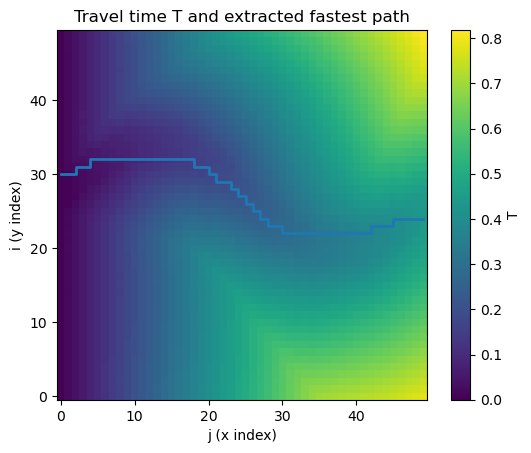

In [1]:
import numpy as np
import heapq
import math

# ----------------------------
# Fast Marching Method (2D isotropic)
# Solves |∇T| = 1/c with T=0 on left boundary (x=0 column)
# ----------------------------

FAR, NARROW, ACCEPTED = 0, 1, 2

def _solve_quadratic_update(ax, ay, f, h):
    """
    Compute one FMM update for T given neighbor minima ax, ay.
    Here f = 1/c is slowness, h grid spacing.
    Standard 2D isotropic upwind update:
      (T-ax)^2 + (T-ay)^2 = (f*h)^2   with T >= max(ax, ay)
    """
    # Sort so ax <= ay
    if ax > ay:
        ax, ay = ay, ax

    fh = f * h

    # Candidate using both directions
    # If the difference is large, solution uses only the smallest neighbor.
    if (ay - ax) >= fh:
        return ax + fh

    # Otherwise solve quadratic:
    # 2T^2 - 2(ax+ay)T + (ax^2 + ay^2 - fh^2) = 0
    # Take the larger root.
    disc = 2.0 * fh * fh - (ay - ax) * (ay - ax)
    if disc < 0:
        # Numerical guard
        disc = 0.0
    return 0.5 * (ax + ay + math.sqrt(disc))


def fast_marching_2d(speed, h=1.0, seed_left_boundary=True):
    """
    speed: (n, n) array, c(x,y) > 0
    h: grid spacing (assumed same in x,y)
    seed_left_boundary: if True, set T=0 for all points on left boundary (col 0)

    returns:
      T: travel time field
    """
    speed = np.asarray(speed, dtype=float)
    if speed.ndim != 2 or speed.shape[0] != speed.shape[1]:
        raise ValueError("speed must be a square 2D array (n x n).")
    if np.any(speed <= 0):
        raise ValueError("All speed values must be > 0.")

    n = speed.shape[0]
    f = 1.0 / speed  # slowness

    T = np.full((n, n), np.inf, dtype=float)
    state = np.full((n, n), FAR, dtype=np.int8)

    heap = []

    def push(i, j, val):
        # Only push if better
        if val < T[i, j]:
            T[i, j] = val
            heapq.heappush(heap, (val, i, j))
            state[i, j] = NARROW

    # Initialize seeds: left boundary (x=0 column)
    if seed_left_boundary:
        for i in range(n):
            T[i, 0] = 0.0
            state[i, 0] = ACCEPTED
        # Initialize neighbors of left boundary into heap
        for i in range(n):
            j = 1
            if j < n:
                # Update (i,1) using accepted neighbor (i,0)
                ax = T[i, 0]
                # ay from vertical accepted neighbors if any
                ay = np.inf
                if i > 0 and state[i - 1, j] == ACCEPTED:
                    ay = min(ay, T[i - 1, j])
                if i + 1 < n and state[i + 1, j] == ACCEPTED:
                    ay = min(ay, T[i + 1, j])
                val = _solve_quadratic_update(ax, ay, f[i, j], h)
                push(i, j, val)
    else:
        raise ValueError("This example is set up for left-boundary seeding. Extend as needed.")

    # Neighbor offsets
    nbrs = [(-1, 0), (1, 0), (0, -1), (0, 1)]

    while heap:
        t, i, j = heapq.heappop(heap)
        if state[i, j] == ACCEPTED:
            continue  # stale heap entry
        # Accept this node
        state[i, j] = ACCEPTED
        T[i, j] = t

        # Update its neighbors
        for di, dj in nbrs:
            ni, nj = i + di, j + dj
            if not (0 <= ni < n and 0 <= nj < n):
                continue
            if state[ni, nj] == ACCEPTED:
                continue
            # Get upwind neighbor minima in x and y directions for (ni,nj)
            # x-direction neighbors: (ni, nj-1) and (ni, nj+1)
            ax = np.inf
            if nj - 1 >= 0 and state[ni, nj - 1] == ACCEPTED:
                ax = min(ax, T[ni, nj - 1])
            if nj + 1 < n and state[ni, nj + 1] == ACCEPTED:
                ax = min(ax, T[ni, nj + 1])

            # y-direction neighbors: (ni-1, nj) and (ni+1, nj)
            ay = np.inf
            if ni - 1 >= 0 and state[ni - 1, nj] == ACCEPTED:
                ay = min(ay, T[ni - 1, nj])
            if ni + 1 < n and state[ni + 1, nj] == ACCEPTED:
                ay = min(ay, T[ni + 1, nj])

            if np.isinf(ax) and np.isinf(ay):
                continue  # cannot update yet

            newT = _solve_quadratic_update(ax, ay, f[ni, nj], h)
            push(ni, nj, newT)

    return T


# ----------------------------
# Path extraction: follow -∇T from right boundary back to left
# ----------------------------

def extract_fastest_path(T, h=1.0, max_steps=200000):
    """
    Choose best starting point on right boundary (col n-1) with minimal T,
    then backtrack to left by stepping to neighbor with lowest T.

    Returns list of (i,j) grid indices from right to left.
    """
    T = np.asarray(T, dtype=float)
    n = T.shape[0]
    jR = n - 1

    # start at minimal travel time on right boundary
    i0 = int(np.argmin(T[:, jR]))
    if not np.isfinite(T[i0, jR]):
        raise RuntimeError("Right boundary has infinite T; check speed field / seeding.")

    path = [(i0, jR)]
    i, j = i0, jR

    nbrs = [(-1, 0), (1, 0), (0, -1), (0, 1)]

    for _ in range(max_steps):
        if j == 0:
            break
        best = (T[i, j], i, j)
        for di, dj in nbrs:
            ni, nj = i + di, j + dj
            if 0 <= ni < n and 0 <= nj < n:
                val = T[ni, nj]
                if val < best[0]:
                    best = (val, ni, nj)

        # If we cannot descend, stop (can happen with plateaus / numerical issues)
        if best[1] == i and best[2] == j:
            break

        i, j = best[1], best[2]
        path.append((i, j))

    return path


# ----------------------------
# Example usage
# ----------------------------
if __name__ == "__main__":
    import matplotlib.pyplot as plt

    n = 50
    l = 1.0
    h = l / (n - 1)

    # Example: random-ish smooth speed field (positive)
    rng = np.random.default_rng(0)
    base = rng.normal(size=(n, n))

    # simple smoothing by repeated local averaging (no scipy dependency)
    speed = np.exp(0.25 * base)  # lognormal-ish, >0
    for _ in range(20):
        speed = 0.25 * (np.roll(speed, 1, 0) + np.roll(speed, -1, 0) +
                        np.roll(speed, 1, 1) + np.roll(speed, -1, 1))

    # Add a fast "channel" to make the path visually interesting
    rr = np.arange(n)
    channel_center = (0.55 * n + 0.15 * n * np.sin(2*np.pi*rr/n)).astype(int)
    for i in range(n):
        c = channel_center[i]
        speed[max(0, c-2):min(n, c+3), i] *= 2.5  # faster band

    # Solve Eikonal
    T = fast_marching_2d(speed, h=h, seed_left_boundary=True)

    # Extract fastest path from right boundary back to left
    path = extract_fastest_path(T, h=h)
    pi = np.array([p[0] for p in path])
    pj = np.array([p[1] for p in path])

    # Plot
    plt.figure()
    plt.imshow(T, origin="lower")
    plt.plot(pj, pi, linewidth=2)
    plt.title("Travel time T and extracted fastest path")
    plt.xlabel("j (x index)")
    plt.ylabel("i (y index)")
    plt.colorbar(label="T")
    plt.show()

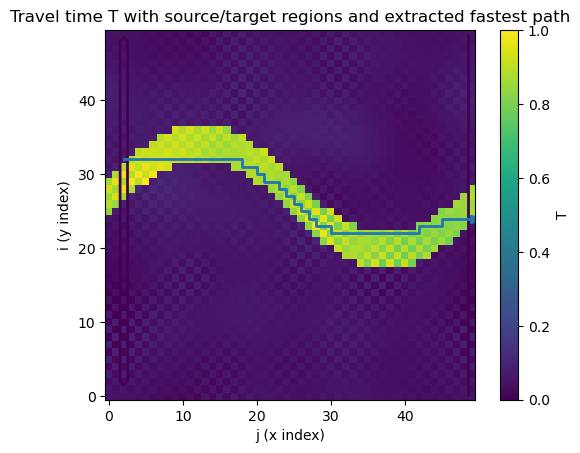

In [12]:
import numpy as np
import heapq
import math

FAR, NARROW, ACCEPTED = 0, 1, 2

def _solve_quadratic_update(ax, ay, f, h):
    """
    Upwind isotropic update for |∇T| = f (where f = 1/c).
    """
    if ax > ay:
        ax, ay = ay, ax
    fh = f * h

    if (ay - ax) >= fh:
        return ax + fh

    disc = 2.0 * fh * fh - (ay - ax) * (ay - ax)
    if disc < 0:
        disc = 0.0
    return 0.5 * (ax + ay + math.sqrt(disc))


def fast_marching_2d_regions(speed, source_mask, h=1.0):
    """
    Solve |∇T| = 1/c for isotropic medium with FMM, with T=0 on source_mask.

    Parameters
    ----------
    speed : (n,n) array, positive speeds c(x,y)>0
    source_mask : (n,n) bool array, True where source region is
    h : float, grid spacing

    Returns
    -------
    T : (n,n) travel time field
    state : (n,n) int8, FAR/NARROW/ACCEPTED (useful for debugging)
    """
    speed = np.asarray(speed, dtype=float)
    if speed.ndim != 2 or speed.shape[0] != speed.shape[1]:
        raise ValueError("speed must be a square 2D array (n x n).")
    if np.any(speed <= 0):
        raise ValueError("All speed values must be > 0.")

    n = speed.shape[0]
    source_mask = np.asarray(source_mask, dtype=bool)
    if source_mask.shape != (n, n):
        raise ValueError("source_mask must have same shape as speed.")
    if not np.any(source_mask):
        raise ValueError("source_mask is empty (no True entries).")

    f = 1.0 / speed  # slowness

    T = np.full((n, n), np.inf, dtype=float)
    state = np.full((n, n), FAR, dtype=np.int8)
    heap = []

    def push(i, j, val):
        if val < T[i, j]:
            T[i, j] = val
            heapq.heappush(heap, (val, i, j))
            state[i, j] = NARROW

    nbrs = [(-1, 0), (1, 0), (0, -1), (0, 1)]

    # 1) Initialize: accept all source cells with T=0
    src_idx = np.argwhere(source_mask)
    for i, j in src_idx:
        T[i, j] = 0.0
        state[i, j] = ACCEPTED

    # 2) Initialize narrow band from source boundary
    for i, j in src_idx:
        for di, dj in nbrs:
            ni, nj = i + di, j + dj
            if 0 <= ni < n and 0 <= nj < n and state[ni, nj] != ACCEPTED:
                # update (ni, nj) using accepted neighbors
                ax = np.inf
                ay = np.inf

                # x-dir neighbors
                if nj - 1 >= 0 and state[ni, nj - 1] == ACCEPTED:
                    ax = min(ax, T[ni, nj - 1])
                if nj + 1 < n and state[ni, nj + 1] == ACCEPTED:
                    ax = min(ax, T[ni, nj + 1])

                # y-dir neighbors
                if ni - 1 >= 0 and state[ni - 1, nj] == ACCEPTED:
                    ay = min(ay, T[ni - 1, nj])
                if ni + 1 < n and state[ni + 1, nj] == ACCEPTED:
                    ay = min(ay, T[ni + 1, nj])

                if np.isinf(ax) and np.isinf(ay):
                    continue

                newT = _solve_quadratic_update(ax, ay, f[ni, nj], h)
                push(ni, nj, newT)

    # 3) Main FMM loop
    while heap:
        t, i, j = heapq.heappop(heap)
        if state[i, j] == ACCEPTED:
            continue
        state[i, j] = ACCEPTED
        T[i, j] = t

        for di, dj in nbrs:
            ni, nj = i + di, j + dj
            if not (0 <= ni < n and 0 <= nj < n):
                continue
            if state[ni, nj] == ACCEPTED:
                continue

            ax = np.inf
            ay = np.inf

            if nj - 1 >= 0 and state[ni, nj - 1] == ACCEPTED:
                ax = min(ax, T[ni, nj - 1])
            if nj + 1 < n and state[ni, nj + 1] == ACCEPTED:
                ax = min(ax, T[ni, nj + 1])

            if ni - 1 >= 0 and state[ni - 1, nj] == ACCEPTED:
                ay = min(ay, T[ni - 1, nj])
            if ni + 1 < n and state[ni + 1, nj] == ACCEPTED:
                ay = min(ay, T[ni + 1, nj])

            if np.isinf(ax) and np.isinf(ay):
                continue

            newT = _solve_quadratic_update(ax, ay, f[ni, nj], h)
            push(ni, nj, newT)

    return T, state


def extract_path_source_to_target(T, source_mask, target_mask, max_steps=200000):
    """
    Backtrack from the best target cell (min T over target_mask) to the source region
    by descending T on the 4-neighborhood.

    Returns
    -------
    path : list of (i,j) indices from target -> source (you can reverse if you want)
    chosen_target : (i,j)
    """
    T = np.asarray(T, dtype=float)
    n = T.shape[0]
    source_mask = np.asarray(source_mask, dtype=bool)
    target_mask = np.asarray(target_mask, dtype=bool)
    if target_mask.shape != (n, n) or source_mask.shape != (n, n):
        raise ValueError("source_mask and target_mask must match T shape.")
    if not np.any(target_mask):
        raise ValueError("target_mask is empty (no True entries).")

    # choose target with minimal T
    Ti = T.copy()
    Ti[~target_mask] = np.inf
    flat = np.argmin(Ti)
    ti = Ti.flat[flat]
    if not np.isfinite(ti):
        raise RuntimeError("No reachable target cell (T=inf on target_mask).")

    i, j = np.unravel_index(flat, T.shape)
    chosen_target = (i, j)

    path = [(i, j)]
    nbrs = [(-1, 0), (1, 0), (0, -1), (0, 1)]

    for _ in range(max_steps):
        if source_mask[i, j]:
            break

        best_val = T[i, j]
        best_ij = (i, j)

        for di, dj in nbrs:
            ni, nj = i + di, j + dj
            if 0 <= ni < n and 0 <= nj < n:
                if T[ni, nj] < best_val:
                    best_val = T[ni, nj]
                    best_ij = (ni, nj)

        if best_ij == (i, j):
            # can't descend further (plateau or discretization issue)
            break

        i, j = best_ij
        path.append((i, j))

    return path, chosen_target


# ----------------------------
# Example usage
# ----------------------------
if __name__ == "__main__":
    import matplotlib.pyplot as plt

    n = 50
    l = 1.0
    h = l / (n - 1)

    rng = np.random.default_rng(1)
    base = rng.normal(size=(n, n))
    speed = np.exp(0.25 * base)
    for _ in range(20):
        speed = 0.25 * (np.roll(speed, 1, 0) + np.roll(speed, -1, 0) +
                        np.roll(speed, 1, 1) + np.roll(speed, -1, 1))

    # Add a fast "channel" to make the path visually interesting
    rr = np.arange(n)
    channel_center = (0.55 * n + 0.15 * n * np.sin(2*np.pi*rr/n)).astype(int)
    for i in range(n):
        c = channel_center[i]
        speed[max(0, c-2):min(n, c+3), i] *= 2.5  # faster band

    # Define source region: a small square on the left-middle
    source_mask = np.zeros((n, n), dtype=bool)
    source_mask[n//20:n - n//20 + 1, n//20] = True

    # Define target region: a small square on the right-middle
    target_mask = np.zeros((n, n), dtype=bool)
    target_mask[:, n - n//20 + 1] = True

    T, _ = fast_marching_2d_regions(speed, source_mask, h=h)
    path, chosen_target = extract_path_source_to_target(T, source_mask, target_mask)

    pi = np.array([p[0] for p in path])
    pj = np.array([p[1] for p in path])

    plt.figure()
    # plt.imshow(T, origin="lower")
    plt.imshow(speed, origin="lower")
    plt.contour(source_mask.astype(float), levels=[0.5], linewidths=2)
    plt.contour(target_mask.astype(float), levels=[0.5], linewidths=2)
    plt.plot(pj, pi, linewidth=2)
    plt.scatter([chosen_target[1]], [chosen_target[0]], s=30)
    plt.title("Travel time T with source/target regions and extracted fastest path")
    plt.xlabel("j (x index)")
    plt.ylabel("i (y index)")
    plt.colorbar(label="T")
    plt.show()


Scanning 1500 paths...


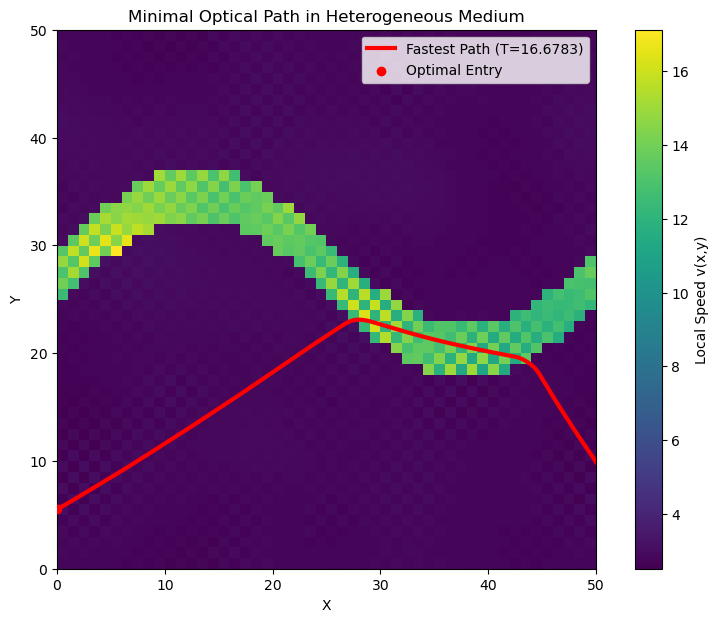

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.interpolate import RegularGridInterpolator

def find_fastest_ray_from_grid(
    V,
    xs,
    ys,
    y_samples,
    angle_samples,
    s_max=None,
    max_step=0.1,
    c=1.0,
):
    V = np.asarray(V)
    xs = np.asarray(xs)
    ys = np.asarray(ys)
    nx, ny = xs.size, ys.size
    L, H = xs[-1], ys[-1]
    
    if s_max is None:
        s_max = L * 2.0  # Ensure ray can cross the whole medium

    # 1. Calculate Gradients (Note: np.gradient returns axis 0 then axis 1)
    # Since V is (ny, nx), axis 0 is y and axis 1 is x.
    hy = ys[1] - ys[0]
    hx = xs[1] - xs[0]
    dVdy, dVdx = np.gradient(V, hy, hx, edge_order=2)

    # 2. Setup Optimized Interpolators
    # RegularGridInterpolator expects (y_grid, x_grid) for a (ny, nx) matrix
    interp_kwargs = {"bounds_error": False, "fill_value": None} # Allow tiny extrapolation
    v_interp = RegularGridInterpolator((ys, xs), V, **interp_kwargs)
    dvx_interp = RegularGridInterpolator((ys, xs), dVdx, **interp_kwargs)
    dvy_interp = RegularGridInterpolator((ys, xs), dVdy, **interp_kwargs)

    def ray_rhs(s, state):
        x, y, vx, vy, t = state
        
        # Interpolate speed and gradient at current (x, y)
        # We pass (y, x) because of the grid ordering
        point = [y, x]
        v_val = v_interp(point)[0]
        dvx = dvx_interp(point)[0]
        dvy = dvy_interp(point)[0]

        # Convert speed gradient to refractive index gradient
        # n = c/v  =>  dn/dx = -c/v^2 * dv/dx
        n_val = c / v_val
        factor = -c / (v_val**2)
        gx, gy = factor * dvx, factor * dvy

        # Ray Equation: d/ds(n*v) = grad(n)
        vdotg = vx * gx + vy * gy
        dvx_ds = (gx - vdotg * vx) / n_val
        dvy_ds = (gy - vdotg * vy) / n_val

        return [vx, vy, dvx_ds, dvy_ds, n_val / c]

    # 3. Define Stopping Events
    def hit_right(s, state): return state[0] - L
    def hit_top(s, state):   return state[1] - H
    def hit_bottom(s, state): return state[1]
    def hit_left(s, state):  return state[0] if s > 0.1 else 1.0 # Ignore start

    for e in [hit_right, hit_top, hit_bottom, hit_left]: e.terminal = True
    hit_right.direction = 1

    # 4. Simulation Wrapper
    def trace_ray(y0, theta):
        state0 = [0.0, y0, np.cos(theta), np.sin(theta), 0.0]
        sol = solve_ivp(
            ray_rhs, (0.0, s_max), state0,
            events=[hit_right, hit_top, hit_bottom, hit_left],
            max_step=max_step, dense_output=True
        )
        
        # Only return successful rays that reached the right wall
        if len(sol.t_events[0]) > 0:
            return {"t": sol.y[4, -1], "sol": sol}
        return None

    # 5. Grid Search
    best = None
    print(f"Scanning {len(y_samples) * len(angle_samples)} paths...")
    
    for y0 in y_samples:
        for theta in angle_samples:
            res = trace_ray(y0, theta)
            if res and (best is None or res["t"] < best["t"]):
                best = {"y0": y0, "theta": theta, **res}

    if best is None:
        raise RuntimeError("No paths reached the right side. Check your speed field or s_max.")

    return best

# --- Example Usage ---
N = 50
L, H = N, N
xs = np.linspace(0, L, N)
ys = np.linspace(0, H, N)
X, Y = np.meshgrid(xs, ys)

# Create a speed field: Light moves faster at the top and bottom, slower in a "blob"
# V_field = 1.0 - 0.5 * np.exp(-((X-5)**2 + (Y-5)**2) / 10) 
V_field = np.exp(speed)

y_starts = np.linspace(0.5, L - 0.5, 50)
angles = np.linspace(-np.deg2rad(45), np.deg2rad(45), 30)

best_ray = find_fastest_ray_from_grid(V_field, xs, ys, y_starts, angles)

# --- Plotting ---
plt.figure(figsize=(10, 7))
# extent sets the physical coordinates for the image
plt.imshow(V_field, origin='lower', extent=[0, L, 0, H], cmap='viridis')
plt.colorbar(label="Local Speed v(x,y)")

# Extract path for plotting
s_vals = np.linspace(0, best_ray["sol"].t[-1], 200)
path = best_ray["sol"].sol(s_vals)
plt.plot(path[0], path[1], 'r-', linewidth=3, label=f"Fastest Path (T={best_ray['t']:.4f})")
plt.scatter(0, best_ray["y0"], color='red', zorder=5, label="Optimal Entry")

plt.title("Minimal Optical Path in Heterogeneous Medium")
plt.xlabel("X")
plt.ylabel("Y")
plt.legend()
plt.show()

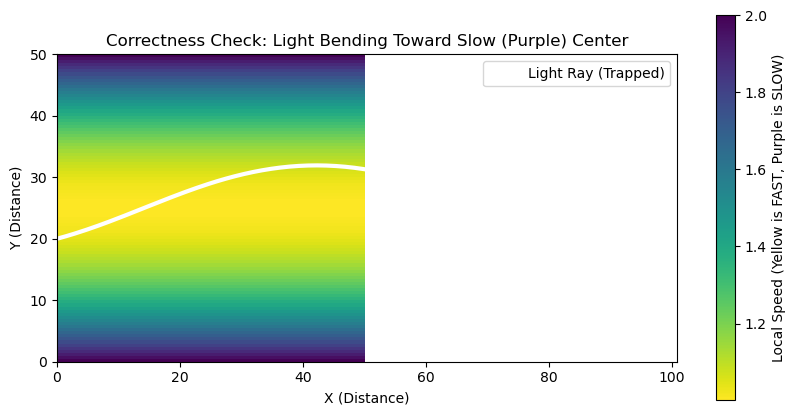

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.interpolate import RegularGridInterpolator

def verify_ray_tracer():
    # 1. Setup a 50x50 Grid
    N = 100
    L, H = 50.0, 50.0
    xs = np.linspace(0, L, N)
    ys = np.linspace(0, H, N)
    X, Y = np.meshgrid(xs, ys)

    # 2. SPEED FIELD: Slow in the middle (v=1.0), Fast at the top/bottom (v=2.0)
    # This creates a "Gravity" effect toward the center for light
    V = 1.0 + 1.0 * (Y - 25)**2 / (25**2) 
    
    # 3. Setup Interpolators
    interp_kwargs = {"bounds_error": False, "fill_value": None}
    v_interp = RegularGridInterpolator((ys, xs), V, **interp_kwargs)
    hy, hx = ys[1]-ys[0], xs[1]-xs[0]
    dVdy, dVdx = np.gradient(V, hy, hx)
    dvx_i = RegularGridInterpolator((ys, xs), dVdx, **interp_kwargs)
    dvy_i = RegularGridInterpolator((ys, xs), dVdy, **interp_kwargs)

    def ray_rhs(s, state):
        x, y, vx, vy, _ = state
        p = [y, x]
        v, dvx, dvy = v_interp(p)[0], dvx_i(p)[0], dvy_i(p)[0]
        # n = 1/v (assuming c=1), dn/dv = -1/v^2
        n_val = 1.0 / v
        gx, gy = (-1.0 / v**2) * dvx, (-1.0 / v**2) * dvy
        vdotg = vx * gx + vy * gy
        return [vx, vy, (gx - vdotg * vx) / n_val, (gy - vdotg * vy) / n_val, n_val]

    # 4. Trace a ray starting at y=20, angled slightly up
    # It should be 'captured' by the slow zone in the middle
    state0 = [0.0, 20.0, np.cos(np.deg2rad(15)), np.sin(np.deg2rad(15)), 0.0]
    sol = solve_ivp(ray_rhs, (0.0, 100.0), state0, 
                    events=lambda s, u: u[0]-L, max_step=0.5, dense_output=True)

    # 5. Visualization
    plt.figure(figsize=(10, 5))
    plt.imshow(V, origin='lower', extent=[0, L, 0, H], cmap='viridis_r') # Inverted so dark=slow
    plt.colorbar(label="Local Speed (Yellow is FAST, Purple is SLOW)")
    
    path = sol.sol(np.linspace(0, sol.t[-1], 200))
    plt.plot(path[0], path[1], 'w-', linewidth=3, label="Light Ray (Trapped)")
    plt.title("Correctness Check: Light Bending Toward Slow (Purple) Center")
    plt.xlabel("X (Distance)"); plt.ylabel("Y (Distance)")
    plt.legend(); plt.show()

verify_ray_tracer()

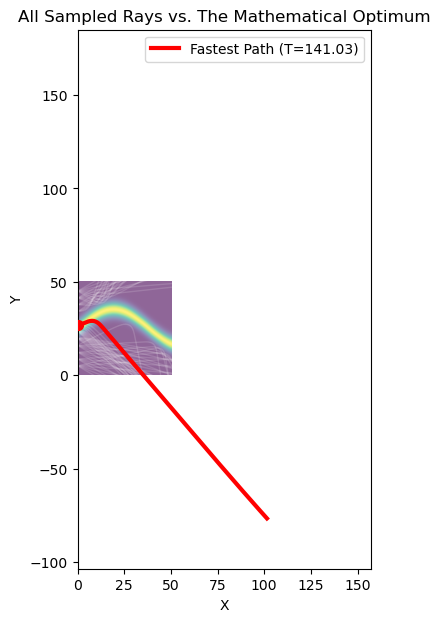

In [22]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.interpolate import RegularGridInterpolator

def visualize_all_rays():
    # 1. Setup Grid and Medium
    N = 100
    L, H = 50.0, 50.0
    xs = np.linspace(0, L, N)
    ys = np.linspace(0, H, N)
    X, Y = np.meshgrid(xs, ys)

    # SPEED FIELD: A "fast lane" (yellow) in a slow medium (purple)
    # V = 1.0 (slow) with a 2.5 (fast) sinusoidal band
    V = 1 + 3.5 * np.exp(-((Y - (25 + 10*np.sin(X/12)))**2) / 15)

    # 2. Interpolators
    interp_kwargs = {"bounds_error": False, "fill_value": None}
    v_i = RegularGridInterpolator((ys, xs), V, **interp_kwargs)
    hy, hx = ys[1]-ys[0], xs[1]-xs[0]
    dVdy, dVdx = np.gradient(V, hy, hx)
    dvx_i = RegularGridInterpolator((ys, xs), dVdx, **interp_kwargs)
    dvy_i = RegularGridInterpolator((ys, xs), dVdy, **interp_kwargs)

    def ray_rhs(s, state):
        x, y, vx, vy, _ = state
        p = [y, x]
        v, dvx, dvy = v_i(p)[0], dvx_i(p)[0], dvy_i(p)[0]
        n_val = 1.0 / v
        gx, gy = (-1.0 / v**2) * dvx, (-1.0 / v**2) * dvy
        vdotg = vx * gx + vy * gy
        return [vx, vy, (gx - vdotg * vx) / n_val, (gy - vdotg * vy) / n_val, n_val]

    # 3. Launch Parameters (Low density for clear visualization)
    y_starts = np.linspace(5, 45, 12)
    angles = np.linspace(-np.deg2rad(30), np.deg2rad(30), 8)

    all_paths = []
    best_ray = None

    # 4. Trace all rays
    for y0 in y_starts:
        for theta in angles:
            state0 = [0.0, y0, np.cos(theta), np.sin(theta), 0.0]
            sol = solve_ivp(ray_rhs, (0.0, 150.0), state0, 
                            events=lambda s, u: u[0]-L, max_step=1.0)
            
            # If hit right wall
            if len(sol.t_events[0]) > 0:
                t_final = sol.y[4, -1]
                path_data = (sol.y[0], sol.y[1])
                all_paths.append((t_final, path_data))
                
                if best_ray is None or t_final < best_ray['t']:
                    best_ray = {'t': t_final, 'path': path_data, 'y0': y0}

    # 5. Plotting
    plt.figure(figsize=(12, 7))
    plt.imshow(V, origin='lower', extent=[0, L, 0, H], cmap='viridis', alpha=0.6)
    
    # Plot all successful rays in semi-transparent white
    for t, (px, py) in all_paths:
        plt.plot(px, py, color='white', alpha=0.15, linewidth=1)

    # Highlight the fastest ray in Red
    if best_ray:
        plt.plot(best_ray['path'][0], best_ray['path'][1], 'red', linewidth=3, 
                 label=f"Fastest Path (T={best_ray['t']:.2f})")
        plt.scatter(0, best_ray['y0'], color='red', s=50, zorder=5)

    plt.title("All Sampled Rays vs. The Mathematical Optimum")
    plt.xlabel("X"); plt.ylabel("Y")
    plt.legend()
    plt.show()

visualize_all_rays()